In [58]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

import geopandas as gpd


sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [59]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [60]:
_id = 'c877xdr4'


In [61]:


model_dir = os.path.join('../models_trained', _id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


    


In [62]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [66]:
x,y = next(iter(val_dl))

In [67]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 16))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



In [65]:
#df = train_dataset.img_labels

#df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])

In [68]:
dataset.img_labels

,driver,sampleid,dataset,country,geometry,block_id,split,split_2
0,coffee,190000000,manual_annotation.csv,Ethiopia,POINT (38.22701 6.19171),155.0,val,1.0
1,coffee,190000001,manual_annotation.csv,Ethiopia,POINT (38.27552 5.95159),155.0,val,1.0
2,coffee,190000002,manual_annotation.csv,Ethiopia,POINT (38.28441 5.95159),155.0,val,1.0
3,coffee,190000003,manual_annotation.csv,Ethiopia,POINT (38.26905 5.94269),155.0,val,1.0
4,coffee,190000004,manual_annotation.csv,Ethiopia,POINT (38.27794 5.94269),155.0,val,1.0
...,...,...,...,...,...,...,...,...
7285,forest plantation,80089201,mapbiomas_indonesia.csv,Indonesia,POINT (117.61713 1.05548),1.0,val,1.0
7286,forest plantation,10655563,mapbiomas.csv,Brazil,POINT (-42.41844 -19.46694),33.0,val,1.0
7287,forest plantation,10656797,mapbiomas.csv,Brazil,POINT (-43.34335 -19.97386),33.0,val,1.0
7288,forest plantation,10653072,mapbiomas.csv,Brazil,POINT (-42.43623 -18.53314),33.0,val,1.0


In [70]:
xx = gpd.read_file('../data/tmp/preds.gpkg')

In [75]:
xx.loc[xx.country == "Ghana"].correct.value_counts()

correct
True     1053
False     184
Name: count, dtype: int64

In [80]:
import torch
torch.set_printoptions(sci_mode=False)

In [81]:
print(expansion_rates)

tensor([    0.5581,     0.0009,     0.0646,     0.0000,     0.0110,        nan,
               nan,     1.7857,     0.0829,        nan,        nan,        nan])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


driver                                             cocoa
sampleid                                        30007912
dataset                                        cocoa.csv
country                                            Ghana
geometry    POINT (-2.3961383843336734 5.59335927243808)
block_id                                           147.0
split                                                val
Name: 2432, dtype: object
tab data:  tensor([    0.2643,     0.0005,     0.0829,     0.0002,     0.1043,        nan,
               nan,     1.6225,     0.0598,        nan,        nan,        nan])
PREDICTION:  cocoa
cocoa


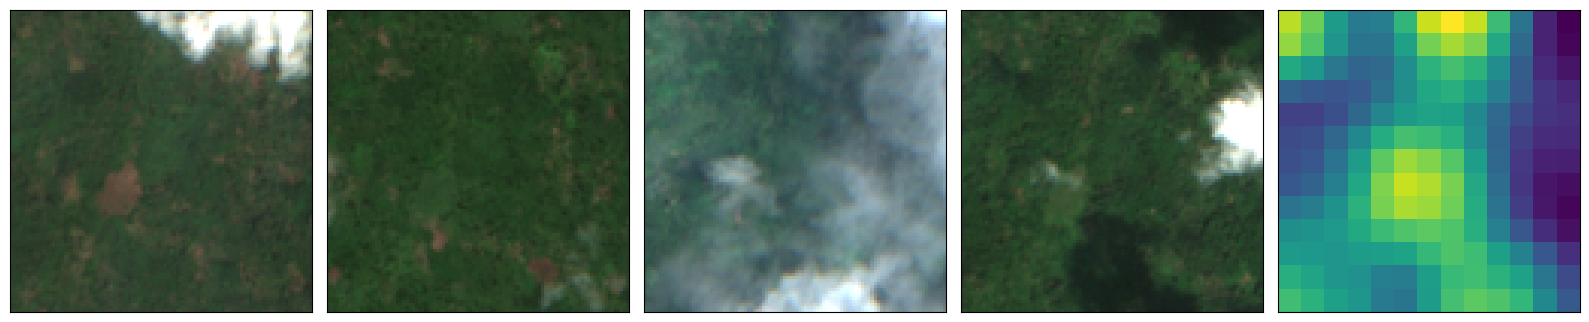

KeyboardInterrupt: Interrupted by user

In [82]:
for _i, row in val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.country == 'Ghana'].iterrows():
    i = row.name
    print(val_dl.dataset.img_labels.iloc[i])
    print("tab data: ", expansion_rates)
    print('PREDICTION: ', xx.loc[xx.sampleid == row.sampleid].preds.values[0])
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 
    

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

driver                                            coffee
sampleid                                       190000251
dataset                            manual_annotation.csv
country                                         Ethiopia
geometry    POINT (35.469560345379854 6.880993470519291)
block_id                                           154.0
split                                                val
Name: 96, dtype: object
PREDICTION:  coffee
coffee


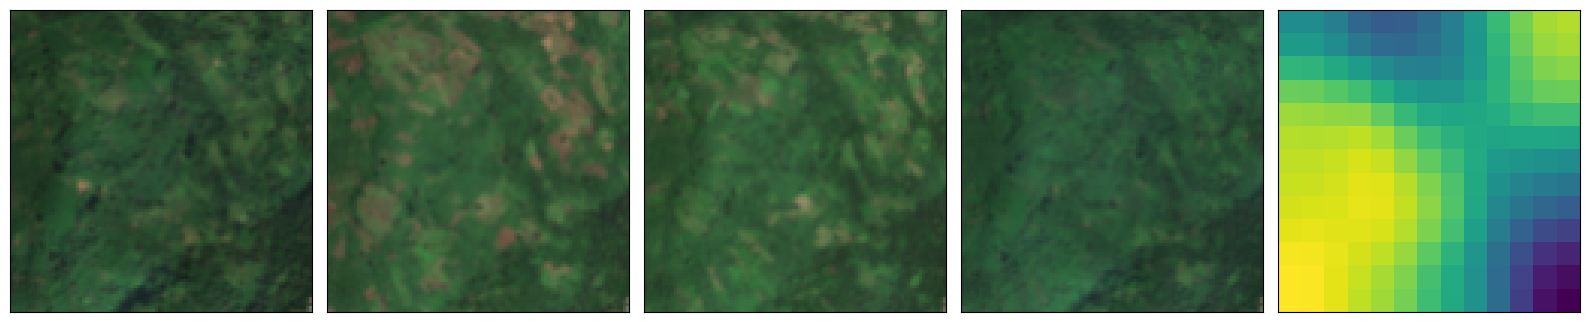

KeyboardInterrupt: Interrupted by user

In [57]:
for _i, row in val_dl.dataset.img_labels.loc[val_dl.dataset.img_labels.country == 'Ethiopia'].iterrows():
    i = row.name
    print(val_dl.dataset.img_labels.iloc[i])
    print('PREDICTION: ', xx.loc[xx.sampleid == row.sampleid].preds.values[0])
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

0

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


80084343
forest plantation


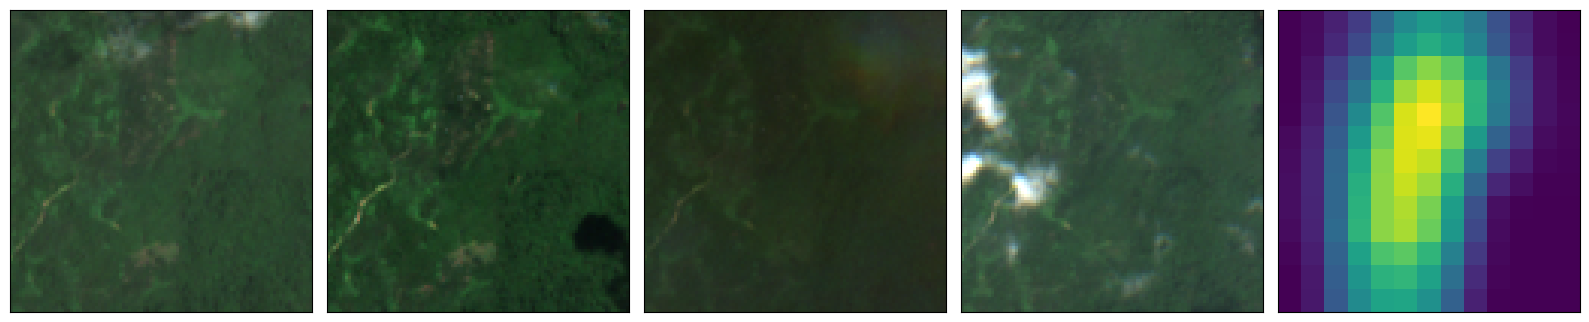

KeyboardInterrupt: Interrupted by user

In [21]:
dataset = val_dl.dataset

while True:

    i = random.randint(0,len(dataset.img_labels))
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    
    
    print(dataset.img_labels.iloc[i].sampleid)
    x, label = val_dl.dataset.__getitem__(i)
    ts, loc, expansion_rates, forestloss = x 

    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [ ]:
sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train


## Visualize time series with TMF